# 4. Starting From the Parent's Weights

> **Overview.** From here on the LTUs search: every 10k steps the weakest are replaced by new ones (generate and
> test), and a new LTU must pick its own first inputs. How should it pick them?

**Setup.** Notebook 2's target and LTUs, with growth, now added at step 0 together with the linear learner. Every 10k
steps the 4 LTUs with the smallest sum of |output weights| are replaced by new ones. A new LTU draws its parent, the
output its shadow weight is on, at random, and first reads 20 inputs. 5 seeds; 500k steps.
- **4a.** The 20 inputs drawn at random, or by the parent's weights; random signs.
- **4b.** Drawn by the parent's weights, with random signs or the parent's signs.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_TARGETS = 8                        # target LTUs
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 10
OUTPUT_FAN_IN = 4                    # target LTUs each output reads, drawn at random
NOISE_STD = 0.1                      # observation noise on each output: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # about the best linear learner's RMSE

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED = 4                         # LTUs replaced at each search step, those with the smallest sum of |output weights|

# --- Experiment ---
LINEAR_STEPS = 0                     # no linear-learner phase: the LTUs are added at step 0
NUM_STEPS = 500_000
NEVER = LINEAR_STEPS + NUM_STEPS     # LTUs added at NEVER: the linear learner alone
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read, 0 elsewhere
    out: jax.Array              # (N_OUTPUTS, N_TARGETS): the outputs' weights, +-1/2 on the target LTUs they read


def make_target(key):
    # Each target LTU reads N_SOURCES inputs and each output OUTPUT_FAN_IN target LTUs, all drawn at random, with
    # random +-1 weights (the outputs' scaled to unit variance).
    read_key, w_key, out_key, out_w_key = jax.random.split(key, 4)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = jax.random.rademacher(w_key, (N_TARGETS, N_INPUTS), dtype=float) * pick(read_key, (N_TARGETS, N_INPUTS), N_SOURCES)
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_TARGETS), dtype=float)
           * pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN) / np.sqrt(OUTPUT_FAN_IN))
    return Target(w, out)


def sample(target, key):
    # One input and its noisy targets.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, target.out @ jnp.where(target.w @ x > 0, 1.0, -1.0) + NOISE_STD * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

Notebook 2's learner. New here: `rewire` makes new LTUs, each with a random parent and its first inputs drawn by
the parent's weights.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1].
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    added: jax.Array            # whether the LTUs feed the outputs yet
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection


def init_net(key, target):
    # Each pair of LTUs wired like one target LTU in turn: reading its inputs and the bias, with LeCun uniform weights;
    # their shadow weights +1 and -1, on a random output that reads that target LTU. Every other weight 0.
    w_key, out_key = jax.random.split(key)
    assigned = jnp.arange(N_LTUS) // 2 % N_TARGETS
    reads = jnp.append(target.w[assigned] != 0, jnp.ones((N_LTUS, 1), bool), axis=1)
    fan_in = N_SOURCES
    readers = target.out[:, assigned] != 0
    parent = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == parent) * jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, jnp.array(False), OPTIMIZER.init(w), stats, shadow, jnp.zeros((N_LTUS, N_INPUTS)))


def add(net):
    # The LTUs start feeding the outputs, the step-sizes of their input weights starting at FAST_STEP_SIZE.
    beta = jnp.where(net.reads.at[:, -1].set(False), jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(added=jnp.array(True), opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def rewire(net, key, replaced, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on a random output, its parent.
    # It reads FAN_IN inputs and the bias, the inputs drawn without replacement with probability proportional to the
    # square of the parent's linear weight on each if parent, uniformly otherwise (Gumbel top-k),
    # with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear weights if signs, at
    # step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and gradient sums fresh.
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.randint(out_key, (N_LTUS,), 0, N_OUTPUTS)
    shadow = jnp.where(replaced, (jnp.arange(N_OUTPUTS)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((N_LTUS, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((N_LTUS, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((N_LTUS, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow, candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each LTU's shadow weight
    # standing in for its weight to its parent in the backward pass while the real one is smaller than 1 in magnitude.
    # Returns the new network and the squared error on this sample averaged over the outputs, before learning from it,
    # and adds dL/dz * x_i to each LTU's gradient sums. `probe` is zero; its gradients are the error arriving at each
    # LTU and dL/dz.

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = (h + probe[0]) * net.added
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(h), mean)

    (loss, (source, h, mean)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': jnp.broadcast_to(source, net.w['output'].shape)}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x), 2 * loss / N_OUTPUTS


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, add_step, searched, parent, signs):
    # NEVER online network-Autostep steps on samples from `target`, the LTUs added at add_step. If searched, they are
    # added as new LTUs (rewired); each then grows every WINDOW steps, and every PERIOD steps the REPLACED LTUs with the
    # smallest sum of |output weights| are replaced by new ones. Returns each window's mean squared error.
    def window(net, inputs):
        index, key = inputs
        wire_key, key = jax.random.split(key)
        start = index * WINDOW == add_step
        net = pick(start, add(net), net)
        # The first LTUs read random inputs with random signs: their parents have no weights yet.
        net = pick(start & searched, rewire(net, wire_key, jnp.ones(N_LTUS, bool), False, False), net)
        net, mse = jax.lax.scan(lambda net, k: learn(net, *sample(target, k)), net, jax.random.split(key, WINDOW))
        since = (index + 1) * WINDOW - add_step
        net = pick(searched & (since > 0), grow(net), net)
        weakest = jnp.zeros(N_LTUS, bool).at[jnp.argsort(jnp.abs(net.w['output'][:, N_INPUTS:-1]).sum(0))[:REPLACED]].set(True)
        due = searched & (since > 0) & (since % PERIOD == 0)
        return pick(due, rewire(net, jax.random.fold_in(wire_key, 1), weakest, parent, signs), net), mse.mean()

    n = NEVER // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(configs):
    # Each (add_step, searched, parent, signs) of configs on N_SEEDS seeds, vmapped together; seed s gives every run the
    # same target network and samples. Returns {config: the RMSE of each window, shaped (seed, window)}.
    add_step, searched, parent, signs, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs
                                                                          for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2))
    nets = jax.vmap(init_net)(keys(0), targets)
    mse = jax.jit(jax.vmap(train))(nets, keys(1), targets, add_step, searched, parent, signs)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [6]:
PROPOSED, NO_SIGNS = (LINEAR_STEPS, True, True, True), (LINEAR_STEPS, True, True, False)
RANDOM = (LINEAR_STEPS, True, False, False)
REFERENCE, LINEAR = (LINEAR_STEPS, False, False, False), (NEVER, False, False, False)
started = perf_counter()
rmse = run([PROPOSED, NO_SIGNS, RANDOM, REFERENCE, LINEAR])
print(f'{len(rmse) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

25 runs in 30s


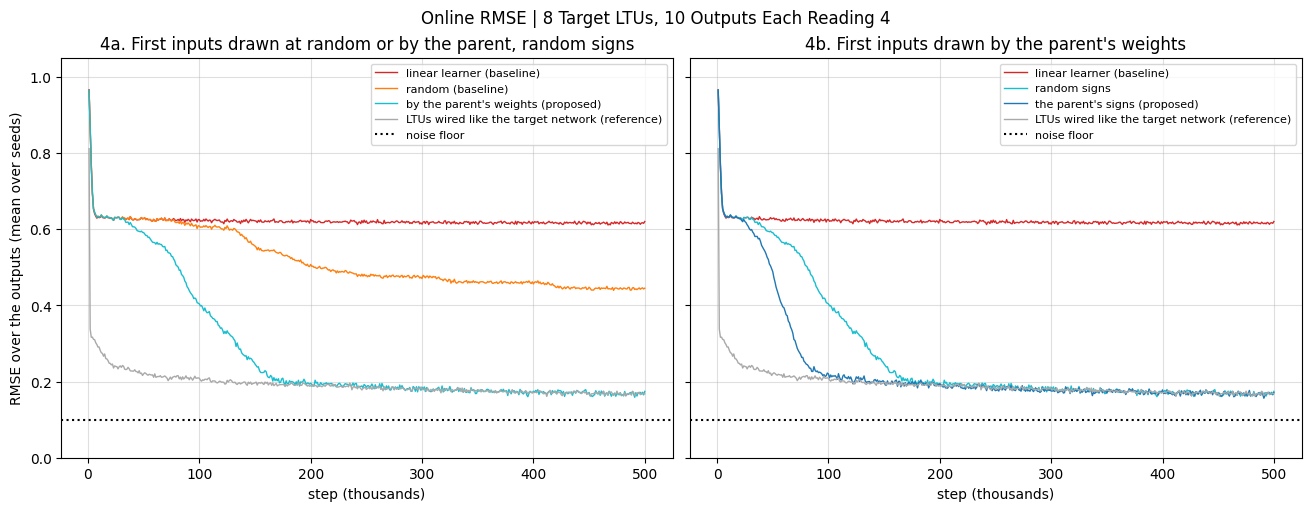

In [7]:
STEPS = (np.arange(NEVER // WINDOW) + 1) * WINDOW


def plot(ax, curves, title):
    # The linear learner, then each (label, config, color) of curves, the reference, and the noise floor: the mean RMSE
    # over seeds.
    for label, config, color in ([('linear learner (baseline)', LINEAR, 'tab:red')] + curves
                                 + [('LTUs wired like the target network (reference)', REFERENCE, 'darkgray')]):
        ax.plot(STEPS / 1000, rmse[config].mean(0), color=color, lw=1, label=label)
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.set(xlabel='step (thousands)', ylim=(0, 1.05), title=title)
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, layout='constrained')
plot(axes[0],
     [('random (baseline)', RANDOM, 'tab:orange'), ("by the parent's weights (proposed)", NO_SIGNS, 'tab:cyan')],
     '4a. First inputs drawn at random or by the parent, random signs')
plot(axes[1], [('random signs', NO_SIGNS, 'tab:cyan'), ("the parent's signs (proposed)", PROPOSED, 'tab:blue')],
     "4b. First inputs drawn by the parent's weights")
axes[0].set_ylabel('RMSE over the outputs (mean over seeds)')
fig.suptitle(f'Online RMSE | {N_TARGETS} Target LTUs, {N_OUTPUTS} Outputs Each Reading {OUTPUT_FAN_IN}')
plt.show()

## Results

- **4a.** First inputs drawn by the parent's weights hold enough of a feature for growth to complete it; random ones get
  only part of the way.
- **4b.** The parent's signs are a heuristic: they speed learning up but do not change where it ends.

## Details

**From step 0.** From here on, the LTUs are added at step 0: the new LTUs search makes join a network that has
already learned anyway, so no linear-learner phase is needed. The first LTUs read random inputs with random signs,
since their parents have no weights yet; search replaces them from 10k steps on.

**Why the parent's weights.** Through the linear learner, the parent already weights the inputs its target LTUs
depend on. A new LTU draws its 20 first inputs without replacement, with probability proportional to the square of
the parent's weight on each. Its weights start LeCun uniform in magnitude; with the parent's signs, each takes the sign
of the parent's weight times its shadow weight. By notebook 1's math, the signs raise the overlap too: on the right
inputs, $m^2 \approx 0.1$ with random signs and $\approx 0.75$ with the right ones.

**The reference** is notebook 1's LTUs at step-size $3 \times 10^{-2}$, reading their target LTU's 10 inputs, with no
growth or search.